# Credit Risk Assessment — Data Cleaning & Preprocessing

## Objective

Prepare the raw dataset for machine learning by:

- removing duplicates
- handling invalid values
- splitting training and test data
- handling missing values
- encoding categorical features
- scaling numerical features where needed

In [1]:
import pandas as pd
import numpy as np

DATA_PATH = "../data/raw/credit_risk_dataset.csv"

df = pd.read_csv(DATA_PATH)

In [2]:
df_clean = df.copy()

In [3]:
df_clean.duplicated().sum()

np.int64(165)

In [4]:
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

In [5]:
df_clean.shape

(32416, 12)

In [6]:
df_clean[df_clean["person_age"] > 100]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32132,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


In [7]:
df_clean = df_clean[df_clean["person_age"] <= 100].reset_index(drop=True)

In [8]:
invalid_emp = df_clean["person_emp_length"] > df_clean["person_age"]

invalid_emp.sum()

np.int64(2)

In [9]:
df_clean.loc[invalid_emp, "person_emp_length"] = np.nan

In [10]:
df_clean.isna().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              889
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3094
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [11]:
(df_clean.isna().mean() * 100).round(2)

person_age                    0.00
person_income                 0.00
person_home_ownership         0.00
person_emp_length             2.74
loan_intent                   0.00
loan_grade                    0.00
loan_amnt                     0.00
loan_int_rate                 9.55
loan_status                   0.00
loan_percent_income           0.00
cb_person_default_on_file     0.00
cb_person_cred_hist_length    0.00
dtype: float64

In [12]:
X = df_clean.drop(columns="loan_status")
y = df_clean["loan_status"]

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [14]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (25928, 11)
X_test: (6483, 11)
y_train: (25928,)
y_test: (6483,)


In [15]:
potential_leakage_cols = [
    "loan_grade",
    "loan_int_rate"
]

X_train = X_train.drop(columns=potential_leakage_cols)
X_test = X_test.drop(columns=potential_leakage_cols)

In [16]:
X_train.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_amnt', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='str')

In [17]:
numeric_features = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

categorical_features = [
    "person_home_ownership",
    "loan_intent",
    "cb_person_default_on_file"
]

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [19]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. 

In [20]:
y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1 Score :", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))

Accuracy : 0.836
Precision: 0.729
Recall   : 0.396
F1 Score : 0.513
ROC-AUC  : 0.8


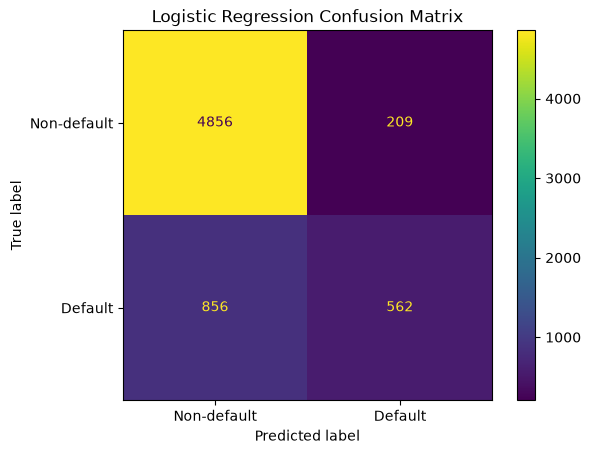

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-default", "Default"]
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()


In [23]:
from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(y_test, y_prob)

print("PR-AUC:", round(pr_auc, 3))

PR-AUC: 0.62


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

random_forest_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. 

In [25]:
rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

In [26]:
print("Accuracy :", round(accuracy_score(y_test, rf_pred), 3))
print("Precision:", round(precision_score(y_test, rf_pred), 3))
print("Recall   :", round(recall_score(y_test, rf_pred), 3))
print("F1 Score :", round(f1_score(y_test, rf_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, rf_prob), 3))
print("PR-AUC   :", round(average_precision_score(y_test, rf_prob), 3))

Accuracy : 0.869
Precision: 0.736
Recall   : 0.623
F1 Score : 0.675
ROC-AUC  : 0.872
PR-AUC   : 0.777


In [27]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [28]:
from xgboost import XGBClassifier

In [29]:
xgb_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. 

In [30]:
xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, xgb_pred), 3))
print("Precision:", round(precision_score(y_test, xgb_pred), 3))
print("Recall   :", round(recall_score(y_test, xgb_pred), 3))
print("F1 Score :", round(f1_score(y_test, xgb_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, xgb_prob), 3))
print("PR-AUC   :", round(average_precision_score(y_test, xgb_prob), 3))

Accuracy : 0.891
Precision: 0.942
Recall   : 0.535
F1 Score : 0.683
ROC-AUC  : 0.897
PR-AUC   : 0.814


In [31]:
X_train_core, X_val, y_train_core, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [32]:
print("Train:", X_train_core.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (20742, 9)
Validation: (5186, 9)
Test: (6483, 9)


In [33]:
from sklearn.base import clone
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_val_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_val_model.fit(X_train_core, y_train_core)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. 

In [34]:
val_prob = xgb_val_model.predict_proba(X_val)[:, 1]

In [35]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]

print("Best Threshold:", round(best_threshold, 3))
print("Precision:", round(precision[best_index], 3))
print("Recall:", round(recall[best_index], 3))
print("F1:", round(f1_scores[best_index], 3))

Best Threshold: 0.344
Precision: 0.767
Recall: 0.612
F1: 0.681


In [36]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Default threshold
val_pred_05 = (val_prob >= 0.50).astype(int)

# Optimized threshold
val_pred_opt = (val_prob >= best_threshold).astype(int)

print("Threshold = 0.50")
print("Precision:", round(precision_score(y_val, val_pred_05), 3))
print("Recall   :", round(recall_score(y_val, val_pred_05), 3))
print("F1       :", round(f1_score(y_val, val_pred_05), 3))

print("\nThreshold =", round(best_threshold, 3))
print("Precision:", round(precision_score(y_val, val_pred_opt), 3))
print("Recall   :", round(recall_score(y_val, val_pred_opt), 3))
print("F1       :", round(f1_score(y_val, val_pred_opt), 3))

Threshold = 0.50
Precision: 0.924
Recall   : 0.511
F1       : 0.658

Threshold = 0.344
Precision: 0.767
Recall   : 0.612
F1       : 0.681


In [37]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss
from sklearn.base import clone

calibrated_xgb = CalibratedClassifierCV(
    estimator=clone(xgb_val_model),
    method="sigmoid",
    cv=5
)

calibrated_xgb.fit(X_train_core, y_train_core)

val_prob_calibrated = calibrated_xgb.predict_proba(X_val)[:, 1]

In [38]:
print(
    "Brier before calibration:",
    round(brier_score_loss(y_val, val_prob), 4)
)

print(
    "Brier after calibration:",
    round(brier_score_loss(y_val, val_prob_calibrated), 4)
)

Brier before calibration: 0.088
Brier after calibration: 0.0891


In [39]:
isotonic_xgb = CalibratedClassifierCV(
    estimator=clone(xgb_val_model),
    method="isotonic",
    cv=5
)

isotonic_xgb.fit(X_train_core, y_train_core)

val_prob_isotonic = isotonic_xgb.predict_proba(X_val)[:, 1]

print(
    "Original:",
    round(brier_score_loss(y_val, val_prob), 4)
)

print(
    "Sigmoid:",
    round(brier_score_loss(y_val, val_prob_calibrated), 4)
)

print(
    "Isotonic:",
    round(brier_score_loss(y_val, val_prob_isotonic), 4)
)

Original: 0.088
Sigmoid: 0.0891
Isotonic: 0.0876


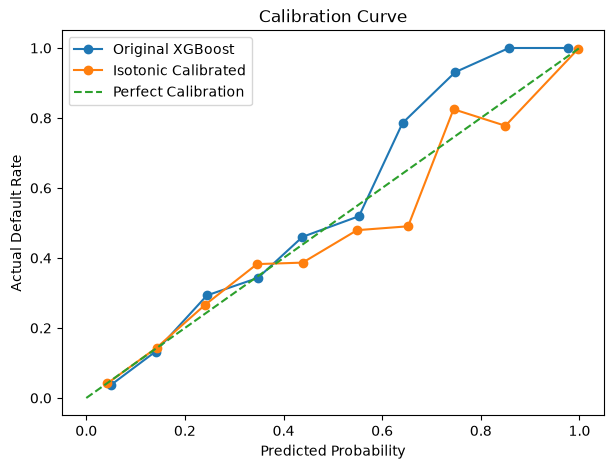

In [40]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true_original, prob_pred_original = calibration_curve(
    y_val,
    val_prob,
    n_bins=10
)

prob_true_isotonic, prob_pred_isotonic = calibration_curve(
    y_val,
    val_prob_isotonic,
    n_bins=10
)

plt.figure(figsize=(7, 5))

plt.plot(
    prob_pred_original,
    prob_true_original,
    marker="o",
    label="Original XGBoost"
)

plt.plot(
    prob_pred_isotonic,
    prob_true_isotonic,
    marker="o",
    label="Isotonic Calibrated"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Predicted Probability")
plt.ylabel("Actual Default Rate")
plt.title("Calibration Curve")
plt.legend()
plt.show()

In [41]:
precision_iso, recall_iso, thresholds_iso = precision_recall_curve(
    y_val,
    val_prob_isotonic
)

f1_iso = (
    2 * precision_iso[:-1] * recall_iso[:-1]
    / (precision_iso[:-1] + recall_iso[:-1] + 1e-10)
)

best_idx_iso = np.argmax(f1_iso)

best_threshold_iso = thresholds_iso[best_idx_iso]

print("Best Threshold:", round(best_threshold_iso, 3))
print("Precision:", round(precision_iso[best_idx_iso], 3))
print("Recall:", round(recall_iso[best_idx_iso], 3))
print("F1:", round(f1_iso[best_idx_iso], 3))


Best Threshold: 0.302
Precision: 0.715
Recall: 0.659
F1: 0.686


In [42]:
from sklearn.metrics import confusion_matrix

thresholds_to_test = np.arange(0.05, 0.81, 0.01)

results = []

for threshold in thresholds_to_test:
    predictions = (val_prob_isotonic >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions
    ).ravel()

    cost = (fn * 5) + (fp * 1)

    results.append({
        "threshold": threshold,
        "cost": cost,
        "false_negatives": fn,
        "false_positives": fp
    })

cost_df = pd.DataFrame(results)

cost_df.sort_values("cost").head(10)

,threshold,cost,false_negatives,false_positives
11,0.16,1910,198,920
13,0.18,1915,225,790
12,0.17,1920,212,860
10,0.15,1922,185,997
14,0.19,1925,239,730
8,0.13,1939,158,1149
15,0.20,1951,258,661
9,0.14,1954,175,1079
16,0.21,1968,272,608
7,0.12,1983,139,1288


In [43]:
business_threshold = cost_df.loc[
    cost_df["cost"].idxmin(),
    "threshold"
]

val_pred_business = (
    val_prob_isotonic >= business_threshold
).astype(int)

print("Business Threshold:", round(business_threshold, 3))
print("Precision:", round(precision_score(y_val, val_pred_business), 3))
print("Recall:", round(recall_score(y_val, val_pred_business), 3))
print("F1:", round(f1_score(y_val, val_pred_business), 3))

tn, fp, fn, tp = confusion_matrix(
    y_val,
    val_pred_business
).ravel()

print("False Negatives:", fn)
print("False Positives:", fp)

Business Threshold: 0.16
Precision: 0.504
Recall: 0.825
F1: 0.626
False Negatives: 198
False Positives: 920


In [44]:
threshold_options = {
    "Default 0.50": 0.50,
    "Best F1": best_threshold_iso,
    "Business Cost": business_threshold
}

comparison = []

for name, threshold in threshold_options.items():
    pred = (val_prob_isotonic >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    comparison.append({
        "strategy": name,
        "threshold": round(threshold, 3),
        "precision": round(precision_score(y_val, pred), 3),
        "recall": round(recall_score(y_val, pred), 3),
        "f1": round(f1_score(y_val, pred), 3),
        "false_negatives": fn,
        "false_positives": fp,
        "business_cost": (fn * 5) + fp
    })

pd.DataFrame(comparison)

,strategy,threshold,precision,recall,f1,false_negatives,false_positives,business_cost
0,Default 0.50,0.500,0.887,0.534,0.666,529,77,2722
1,Best F1,0.302,0.715,0.659,0.686,387,298,2233
2,Business Cost,0.160,0.504,0.825,0.626,198,920,1910


In [45]:
test_prob = isotonic_xgb.predict_proba(X_test)[:, 1]

final_threshold = best_threshold_iso

test_pred = (test_prob >= final_threshold).astype(int)

In [46]:
print("Final Threshold:", round(final_threshold, 3))
print("Accuracy :", round(accuracy_score(y_test, test_pred), 3))
print("Precision:", round(precision_score(y_test, test_pred), 3))
print("Recall   :", round(recall_score(y_test, test_pred), 3))
print("F1 Score :", round(f1_score(y_test, test_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, test_prob), 3))
print("PR-AUC   :", round(average_precision_score(y_test, test_prob), 3))
print("Brier    :", round(brier_score_loss(y_test, test_prob), 4))

Final Threshold: 0.302
Accuracy : 0.872
Precision: 0.718
Recall   : 0.68
F1 Score : 0.699
ROC-AUC  : 0.894
PR-AUC   : 0.809
Brier    : 0.0842


In [47]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred
).ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

True Negatives : 4687
False Positives: 378
False Negatives: 454
True Positives : 964


In [48]:
import shap

fitted_preprocessor = xgb_val_model.named_steps["preprocessor"]
fitted_xgb = xgb_val_model.named_steps["classifier"]

X_test_transformed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

print("Number of model features:", len(feature_names))
print(feature_names)

Number of model features: 18
['num__person_age' 'num__person_income' 'num__person_emp_length'
 'num__loan_amnt' 'num__loan_percent_income'
 'num__cb_person_cred_hist_length' 'cat__person_home_ownership_MORTGAGE'
 'cat__person_home_ownership_OTHER' 'cat__person_home_ownership_OWN'
 'cat__person_home_ownership_RENT' 'cat__loan_intent_DEBTCONSOLIDATION'
 'cat__loan_intent_EDUCATION' 'cat__loan_intent_HOMEIMPROVEMENT'
 'cat__loan_intent_MEDICAL' 'cat__loan_intent_PERSONAL'
 'cat__loan_intent_VENTURE' 'cat__cb_person_default_on_file_N'
 'cat__cb_person_default_on_file_Y']


In [49]:
explainer = shap.TreeExplainer(fitted_xgb)

shap_values = explainer(X_test_transformed)

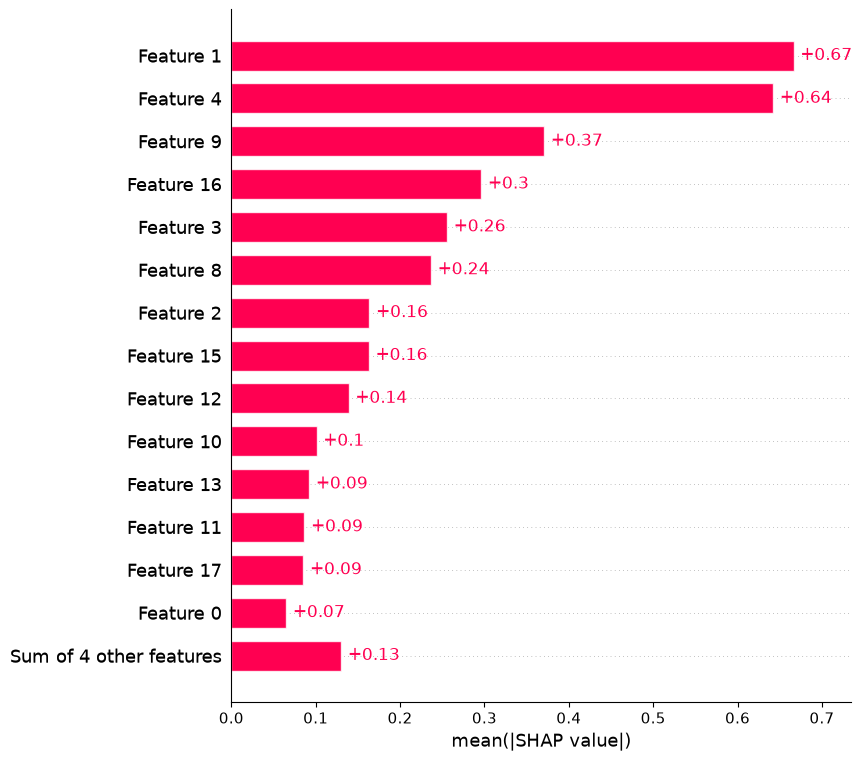

In [50]:
shap.plots.bar(
    shap_values,
    max_display=15
)

In [51]:
import pandas as pd

# Convert transformed data to a DataFrame with real feature names
X_test_shap = pd.DataFrame(
    X_test_transformed.toarray()
    if hasattr(X_test_transformed, "toarray")
    else X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

# Clean prefixes added by ColumnTransformer
X_test_shap.columns = [
    col.replace("num__", "").replace("cat__", "")
    for col in X_test_shap.columns
]

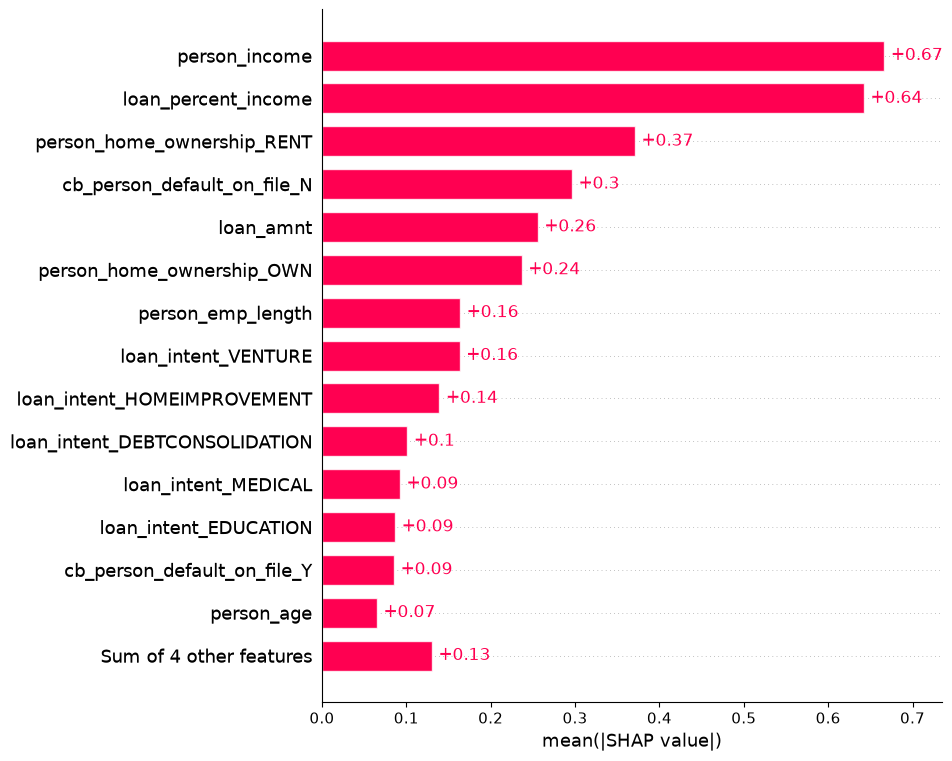

In [52]:
explainer = shap.TreeExplainer(fitted_xgb)
shap_values = explainer(X_test_shap)

shap.plots.bar(
    shap_values,
    max_display=15
)

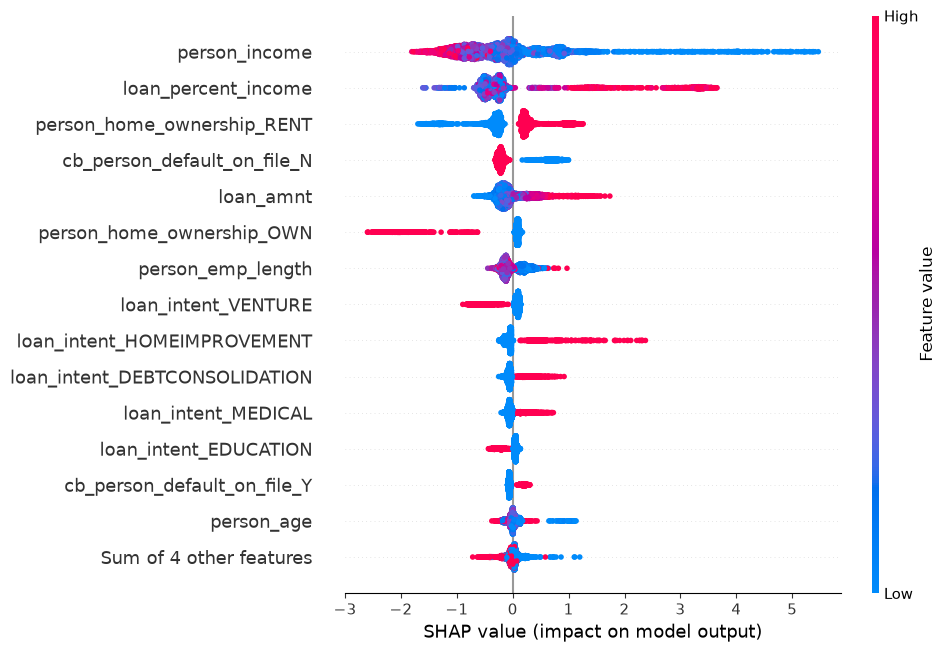

In [53]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

In [54]:
# Find the borrower with the highest calibrated default probability
local_idx = int(np.argmax(test_prob))

applicant_index = X_test.index[local_idx]

print("Applicant data:")
display(X_test.loc[[applicant_index]])

print(
    "Calibrated default probability:",
    round(test_prob[local_idx], 3)
)

Applicant data:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_amnt,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
31483,43,47840,RENT,27.0,PERSONAL,15000,0.31,N,12


Calibrated default probability: 1.0


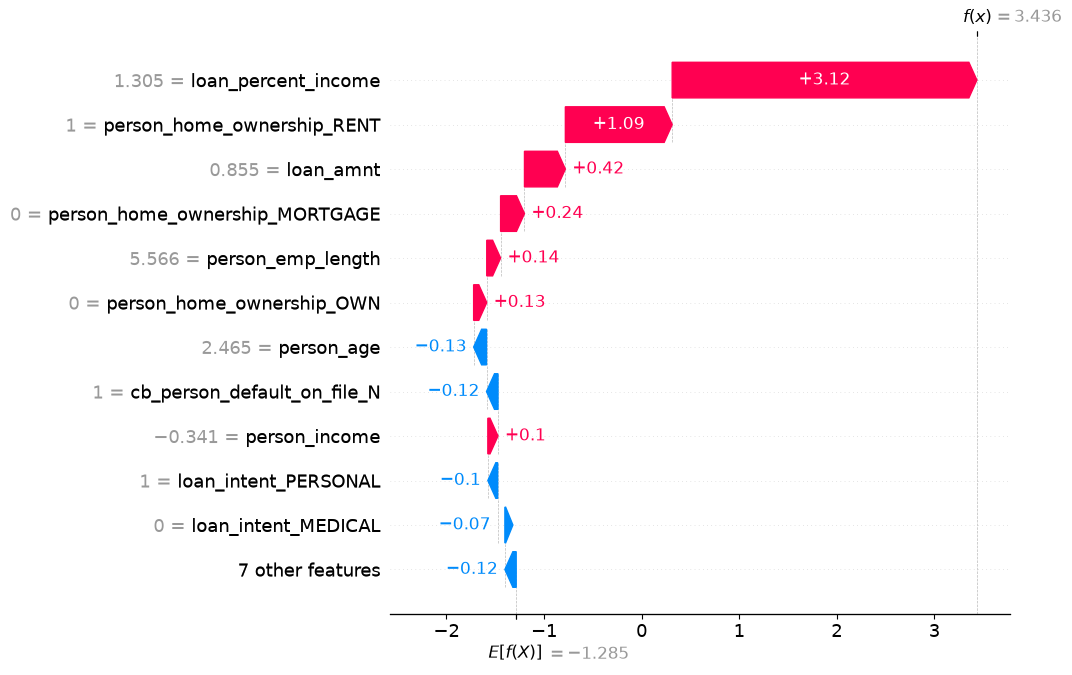

In [55]:
shap.plots.waterfall(
    shap_values[local_idx],
    max_display=12
)

In [56]:
applicant = X_test.loc[[applicant_index]]

display(applicant.T)

raw_probability = xgb_val_model.predict_proba(applicant)[0, 1]
calibrated_probability = isotonic_xgb.predict_proba(applicant)[0, 1]

print("Raw XGBoost probability:", round(raw_probability, 3))
print("Calibrated probability:", round(calibrated_probability, 3))
print("Decision threshold:", round(best_threshold_iso, 3))
print(
    "Decision:",
    "High Risk" if calibrated_probability >= best_threshold_iso
    else "Low Risk"
)

,31483
person_age,43
person_income,47840
person_home_ownership,RENT
person_emp_length,27.0
loan_intent,PERSONAL
loan_amnt,15000
loan_percent_income,0.31
cb_person_default_on_file,N
cb_person_cred_hist_length,12


Raw XGBoost probability: 0.969
Calibrated probability: 1.0
Decision threshold: 0.302
Decision: High Risk


In [57]:
local_shap = pd.DataFrame({
    "feature": X_test_shap.columns,
    "shap_value": shap_values[local_idx].values
})

local_shap["impact"] = local_shap["shap_value"].abs()

local_shap = local_shap.sort_values(
    "impact",
    ascending=False
)

local_shap.head(10)

,feature,shap_value,impact
4,loan_percent_income,3.122708,3.122708
9,person_home_ownership_RENT,1.094763,1.094763
3,loan_amnt,0.419001,0.419001
6,person_home_ownership_MORTGAGE,0.244616,0.244616
2,person_emp_length,0.141831,0.141831
8,person_home_ownership_OWN,0.134520,0.134520
0,person_age,-0.131926,0.131926
16,cb_person_default_on_file_N,-0.117652,0.117652
1,person_income,0.103994,0.103994
14,loan_intent_PERSONAL,-0.100548,0.100548


In [58]:
def get_original_feature(feature_name):
    for col in categorical_features:
        if feature_name.startswith(col + "_"):
            return col
    return feature_name


local_shap = pd.DataFrame({
    "feature": X_test_shap.columns,
    "shap_value": shap_values[local_idx].values
})

local_shap["original_feature"] = local_shap["feature"].apply(
    get_original_feature
)

aggregated_shap = (
    local_shap
    .groupby("original_feature", as_index=False)["shap_value"]
    .sum()
)

aggregated_shap["impact"] = aggregated_shap["shap_value"].abs()

aggregated_shap = aggregated_shap.sort_values(
    "impact",
    ascending=False
)

aggregated_shap

,original_feature,shap_value,impact
4,loan_percent_income,3.122708,3.122708
7,person_home_ownership,1.470448,1.470448
2,loan_amnt,0.419001,0.419001
3,loan_intent,-0.202164,0.202164
1,cb_person_default_on_file,-0.154788,0.154788
6,person_emp_length,0.141831,0.141831
5,person_age,-0.131926,0.131926
8,person_income,0.103994,0.103994
0,cb_person_cred_hist_length,-0.047795,0.047795


In [59]:
applicant_values = X_test.loc[applicant_index]

aggregated_shap["actual_value"] = aggregated_shap[
    "original_feature"
].map(applicant_values)

aggregated_shap[
    ["original_feature", "actual_value", "shap_value", "impact"]
].head(8)

,original_feature,actual_value,shap_value,impact
4,loan_percent_income,0.31,3.122708,3.122708
7,person_home_ownership,RENT,1.470448,1.470448
2,loan_amnt,15000,0.419001,0.419001
3,loan_intent,PERSONAL,-0.202164,0.202164
1,cb_person_default_on_file,N,-0.154788,0.154788
6,person_emp_length,27.0,0.141831,0.141831
5,person_age,43,-0.131926,0.131926
8,person_income,47840,0.103994,0.103994


In [60]:
def format_feature_value(feature, value):
    if feature in ["person_income", "loan_amnt"]:
        return f"${float(value):,.0f}"

    if feature == "loan_percent_income":
        return f"{float(value) * 100:.0f}%"

    if feature == "cb_person_default_on_file":
        return "Yes" if value == "Y" else "No"

    return str(value)

In [61]:
def create_risk_explanation(aggregated_shap, applicant_values, top_n=3):

    explanation = aggregated_shap.copy()

    explanation["actual_value"] = explanation[
        "original_feature"
    ].map(applicant_values)

    increasing = (
        explanation[explanation["shap_value"] > 0]
        .sort_values("shap_value", ascending=False)
        .head(top_n)
    )

    decreasing = (
        explanation[explanation["shap_value"] < 0]
        .sort_values("shap_value")
        .head(top_n)
    )

    return {
        "increasing_risk": [
            {
                "feature": row["original_feature"],
                "value": format_feature_value(
                    row["original_feature"],
                    row["actual_value"]
                )
            }
            for _, row in increasing.iterrows()
        ],

        "decreasing_risk": [
            {
                "feature": row["original_feature"],
                "value": format_feature_value(
                    row["original_feature"],
                    row["actual_value"]
                )
            }
            for _, row in decreasing.iterrows()
        ]
    }

In [62]:
def get_original_feature(feature_name):
    for col in categorical_features:
        if feature_name.startswith(col + "_"):
            return col
    return feature_name


local_shap = pd.DataFrame({
    "feature": X_test_shap.columns,
    "shap_value": shap_values[local_idx].values
})

local_shap["original_feature"] = local_shap["feature"].apply(
    get_original_feature
)

aggregated_shap = (
    local_shap
    .groupby("original_feature", as_index=False)["shap_value"]
    .sum()
)

aggregated_shap["impact"] = aggregated_shap["shap_value"].abs()

aggregated_shap = aggregated_shap.sort_values(
    "impact",
    ascending=False
)

applicant_values = X_test.loc[applicant_index]

In [63]:
explanation = create_risk_explanation(
    aggregated_shap,
    applicant_values
)

explanation

{'increasing_risk': [{'feature': 'loan_percent_income', 'value': '31%'},
  {'feature': 'person_home_ownership', 'value': 'RENT'},
  {'feature': 'loan_amnt', 'value': '$15,000'}],
 'decreasing_risk': [{'feature': 'loan_intent', 'value': 'PERSONAL'},
  {'feature': 'cb_person_default_on_file', 'value': 'No'},
  {'feature': 'person_age', 'value': '43'}]}

In [64]:
import joblib

joblib.dump(
    isotonic_xgb,
    "../artifacts/credit_risk_model.pkl"
)

joblib.dump(
    best_threshold_iso,
    "../artifacts/decision_threshold.pkl"
)

['../artifacts/decision_threshold.pkl']